# Early Warning Signs of Business Closure
## Initial exploratory data analysis

This notebook describes the filtered Yelp restaurant data currently available in `data/`. It summarizes restaurant status, data quality, business-level review summaries, and check-in timing. It does **not** train models, classify businesses, cluster observations, analyze sentiment, or infer closure dates.

**Interpretation caution:** Yelp's `is_open` field is a current label, not a closure date. Differences between businesses currently labeled open and closed are descriptive associations only; they do not show that a change preceded closure or predict closure.

All four compressed datasets are available. Reviews are processed in one streaming pass; only counts, rating sums, and small frequency tables are retained, never review text or a list of all reviews.

## 1. Locate and inspect the filtered data

The notebook reads compressed JSON Lines files in place and does not change them. It searches the current directory and its parent so it can be run from either the repository root or `analysis/`. An absent file or a Git LFS pointer is reported as unavailable; no substitute or synthetic observations are created.

In [1]:
from collections import Counter, defaultdict
from datetime import datetime
import gzip
import json
import math
import statistics
from pathlib import Path

import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in candidates if (p / "data").is_dir()), Path.cwd())
DATA_DIR = REPO_ROOT / "data"
DATASETS = {
    "businesses": DATA_DIR / "businesses.jsonl.gz",
    "reviews": DATA_DIR / "reviews.jsonl.gz",
    "checkins": DATA_DIR / "checkins.jsonl.gz",
    "tips": DATA_DIR / "tips.jsonl.gz",
}

def availability(path):
    if not path.is_file():
        return "missing"
    with path.open("rb") as stream:
        prefix = stream.read(256)
    if prefix.startswith(b"version https://git-lfs.github.com/spec/v1"):
        return "Git LFS pointer (file content not present)"
    return "present"

for name, path in DATASETS.items():
    print(f"{name:12} {availability(path):38} {path}")

def read_jsonl_gz(path):
    with gzip.open(path, "rt", encoding="utf-8") as stream:
        for line_number, line in enumerate(stream, start=1):
            if not line.strip():
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path.name} at line {line_number}") from exc

if availability(DATASETS["businesses"]) != "present":
    raise FileNotFoundError(f"Filtered businesses dataset is unavailable: {DATASETS['businesses']}")

businesses = list(read_jsonl_gz(DATASETS["businesses"]))
print(f"\nLoaded {len(businesses):,} business records.")

businesses   present                                /Users/emilyehrenberg/Projects/business-closure-project/data/businesses.jsonl.gz
reviews      present                                /Users/emilyehrenberg/Projects/business-closure-project/data/reviews.jsonl.gz
checkins     present                                /Users/emilyehrenberg/Projects/business-closure-project/data/checkins.jsonl.gz
tips         present                                /Users/emilyehrenberg/Projects/business-closure-project/data/tips.jsonl.gz

Loaded 52,268 business records.


## 2. Restaurant totals and basic data quality

The business file is treated as one row per filtered restaurant. Status counts use the observed `is_open` values (`1` = currently open, `0` = currently closed); unexpected or missing values are kept visible rather than silently recoded. Missingness counts nulls and blank strings.

In [2]:
business_ids = [row.get("business_id") for row in businesses]
valid_business_ids = [i for i in business_ids if isinstance(i, str) and bool(i.strip())]
duplicate_id_count = len(valid_business_ids) - len(set(valid_business_ids))
status_counts = Counter(row.get("is_open") for row in businesses)
print(f"Missing/blank business IDs: {len(business_ids) - len(valid_business_ids):,}")
print(f"Records without Restaurants category: {sum("Restaurants" not in (r.get("categories") or "").split(", ") for r in businesses):,}")
print(f"Total restaurant records: {len(businesses):,}")
print(f"Unique non-missing business IDs: {len(set(i for i in business_ids if i is not None)):,}")
print(f"Duplicate business IDs (beyond first occurrence): {duplicate_id_count:,}")
print(f"Currently open (is_open=1): {status_counts.get(1, 0):,}")
print(f"Currently closed (is_open=0): {status_counts.get(0, 0):,}")
print(f"Missing/unexpected is_open values: {sum(n for status, n in status_counts.items() if status not in (0, 1)):,}")
print("Observed is_open values:", dict(status_counts))

def is_missing(value):
    return value is None or (isinstance(value, str) and not value.strip())

all_fields = sorted({field for row in businesses for field in row})
missingness = []
for field in all_fields:
    missing = sum(is_missing(row.get(field)) for row in businesses)
    missingness.append((field, missing, 100 * missing / len(businesses) if businesses else math.nan))
print("\nMissing / blank values by business field:")
for field, count, percent in sorted(missingness, key=lambda item: (-item[1], item[0])):
    print(f"{field:18} {count:>8,}  ({percent:5.1f}%)")

def numeric_values(field):
    values = []
    invalid = 0
    for row in businesses:
        value = row.get(field)
        if value is None:
            continue
        try:
            number = float(value)
            if math.isfinite(number):
                values.append(number)
            else:
                invalid += 1
        except (TypeError, ValueError):
            invalid += 1
    return values, invalid

stars_values, invalid_stars = numeric_values("stars")
review_count_values, invalid_review_counts = numeric_values("review_count")
invalid_coordinates = 0
for row in businesses:
    lat, lon = row.get("latitude"), row.get("longitude")
    if lat is None or lon is None:
        continue
    try:
        if not (-90 <= float(lat) <= 90 and -180 <= float(lon) <= 180):
            invalid_coordinates += 1
    except (TypeError, ValueError):
        invalid_coordinates += 1

print("\nBasic range checks:")
print(f"Stars outside 1–5: {sum(not 1 <= x <= 5 for x in stars_values):,}; unparseable/non-finite: {invalid_stars:,}")
print(f"Negative business review_count: {sum(x < 0 for x in review_count_values):,}; unparseable/non-finite: {invalid_review_counts:,}")
print(f"Invalid coordinate pairs (among records with both coordinates): {invalid_coordinates:,}")

Missing/blank business IDs: 0
Records without Restaurants category: 0
Total restaurant records: 52,268
Unique non-missing business IDs: 52,268
Duplicate business IDs (beyond first occurrence): 0
Currently open (is_open=1): 34,987
Currently closed (is_open=0): 17,281
Missing/unexpected is_open values: 0
Observed is_open values: {1: 34987, 0: 17281}

Missing / blank values by business field:
hours                 7,278  ( 13.9%)
attributes              565  (  1.1%)
address                 443  (  0.8%)
postal_code              21  (  0.0%)
business_id               0  (  0.0%)
categories                0  (  0.0%)
city                      0  (  0.0%)
is_open                   0  (  0.0%)
latitude                  0  (  0.0%)
longitude                 0  (  0.0%)
name                      0  (  0.0%)
review_count              0  (  0.0%)
stars                     0  (  0.0%)
state                     0  (  0.0%)

Basic range checks:
Stars outside 1–5: 0; unparseable/non-finite: 0
Negati

## 3. Business-level review counts and star ratings

The business file includes `review_count` and `stars`, which are useful current business-level summaries. They are not a substitute for individual review records: the review dates and per-review ratings are needed for review timelines. Summary statistics and plots below describe restaurants, not individual reviews.

Business-level review_count: n=52,268; mean=87.27; median=33.00; min=5.00; max=7568.00
Business-level stars:        n=52,268; mean=3.52; median=3.50; min=1.00; max=5.00

Business star-value distribution:
  1.0 stars: 247
  1.5 stars: 1,481
  2.0 stars: 2,909
  2.5 stars: 4,850
  3.0 stars: 7,639
  3.5 stars: 11,794
  4.0 stars: 13,438
  4.5 stars: 8,357
  5.0 stars: 1,553


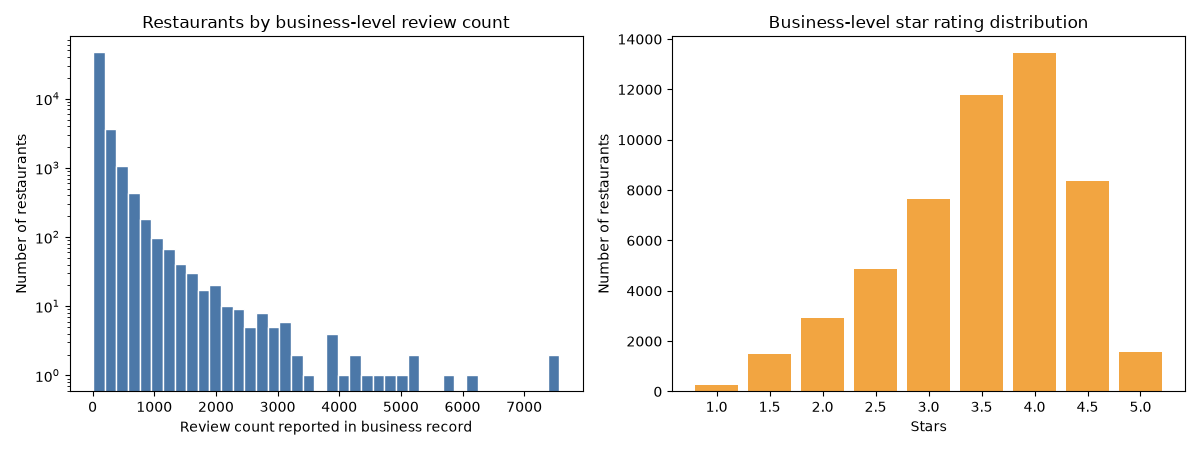

In [3]:
def describe(values):
    if not values:
        return "No valid observations."
    return (f"n={len(values):,}; mean={statistics.mean(values):.2f}; "
            f"median={statistics.median(values):.2f}; min={min(values):.2f}; max={max(values):.2f}")

print("Business-level review_count:", describe(review_count_values))
print("Business-level stars:       ", describe(stars_values))
business_star_counts = Counter(row.get("stars") for row in businesses if row.get("stars") is not None)
print("\nBusiness star-value distribution:")
for rating in sorted(business_star_counts):
    print(f"{rating!s:>5} stars: {business_star_counts[rating]:,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist([x for x in review_count_values if x >= 0], bins=40, color="#4C78A8", edgecolor="white")
axes[0].set_title("Restaurants by business-level review count")
axes[0].set_xlabel("Review count reported in business record")
axes[0].set_ylabel("Number of restaurants")
axes[0].set_yscale("log")
axes[1].bar([str(value) for value in sorted(business_star_counts)],
            [business_star_counts[value] for value in sorted(business_star_counts)],
            color="#F2A541")
axes[1].set_title("Business-level star rating distribution")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("Number of restaurants")
fig.tight_layout()
plt.show()

## 4. Compare business-level summaries by current status

This is a cross-sectional comparison by the current `is_open` label. It uses each restaurant's stored review count and business-level star rating; no temporal ordering or closure date is available from these fields.

Currently open (n=34,987):
  Business review_count: n=34,987; mean=104.14; median=40.00; min=5.00; max=7568.00
  Business stars:        n=34,987; mean=3.52; median=3.50; min=1.00; max=5.00
Currently closed (n=17,281):
  Business review_count: n=17,281; mean=53.10; median=24.00; min=5.00; max=1781.00
  Business stars:        n=17,281; mean=3.50; median=3.50; min=1.00; max=5.00


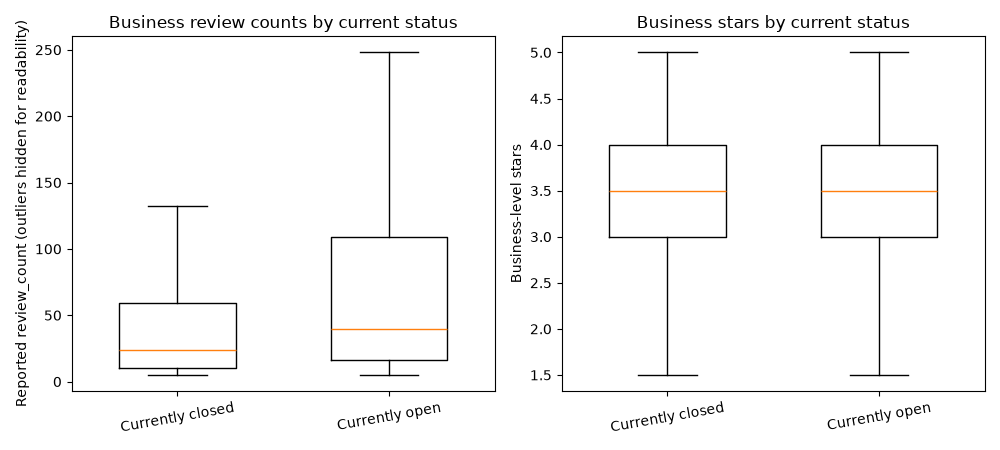

In [4]:
status_labels = {1: "Currently open", 0: "Currently closed"}
business_summary_by_status = {}
for status, label in status_labels.items():
    rows = [row for row in businesses if row.get("is_open") == status]
    counts = [float(row["review_count"]) for row in rows if row.get("review_count") is not None]
    ratings = [float(row["stars"]) for row in rows if row.get("stars") is not None]
    business_summary_by_status[status] = (rows, counts, ratings)
    print(f"{label} (n={len(rows):,}):")
    print(f"  Business review_count: {describe(counts)}")
    print(f"  Business stars:        {describe(ratings)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for status, label in status_labels.items():
    rows, counts, ratings = business_summary_by_status[status]
    axes[0].boxplot(counts, positions=[status + 1], widths=0.55, showfliers=False)
    axes[1].boxplot(ratings, positions=[status + 1], widths=0.55, showfliers=False)
for axis in axes:
    axis.set_xticks([1, 2], ["Currently closed", "Currently open"])
    axis.tick_params(axis="x", rotation=10)
axes[0].set_title("Business review counts by current status")
axes[0].set_ylabel("Reported review_count (outliers hidden for readability)")
axes[1].set_title("Business stars by current status")
axes[1].set_ylabel("Business-level stars")
fig.tight_layout()
plt.show()

## 5. Check-in date range and monthly activity

Check-in records contain comma-separated timestamps. The code parses valid timestamps to describe the observed range and monthly check-in event counts. These are check-ins, **not reviews**, and should not be interpreted as review activity. Counts aggregate events across restaurants; they are not normalized for the number of restaurants or platform usage.

Check-in records with unmatched business IDs: 0
Check-in records with empty date strings: 0
Restaurants with valid check-ins: 51,302 / 52,268
Check-in business records: 51,302
Valid timestamped check-in events: 8,515,127
Unparseable timestamps: 0
Check-in date range: 2009-12-30 02:53:27 to 2022-01-19 16:48:37
Check-in event counts grouped by associated current status: {1: 6757093, 0: 1758034}


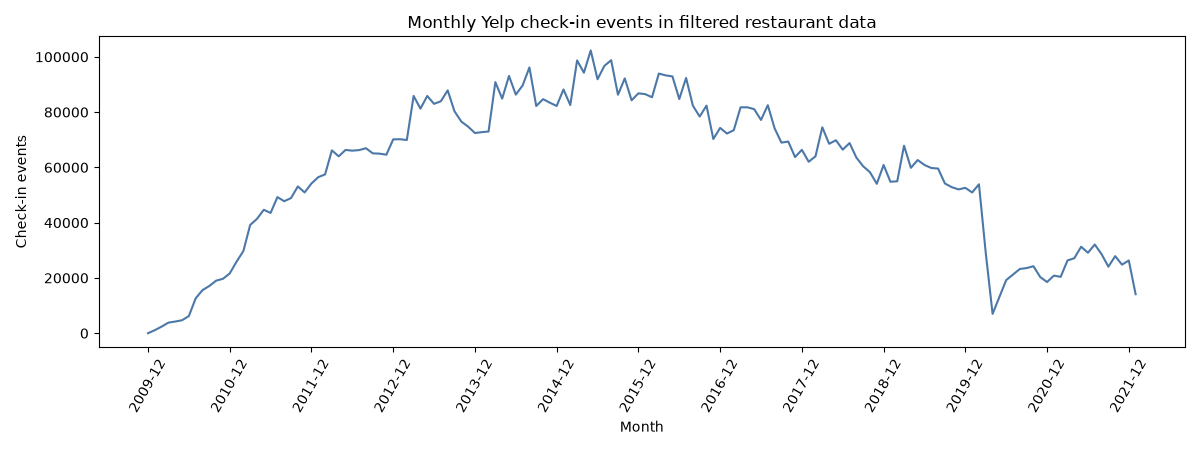

In [5]:
checkin_month_counts = Counter()
checkin_status_counts = Counter()
checkin_date_min = None
checkin_date_max = None
checkin_record_count = 0
checkin_event_count = 0
checkin_bad_timestamp_count = 0
checkins_by_business = Counter()
checkin_unmatched_records = 0
checkin_empty_records = 0

if availability(DATASETS["checkins"]) == "present":
    business_status = {row.get("business_id"): row.get("is_open") for row in businesses}
    for record in read_jsonl_gz(DATASETS["checkins"]):
        checkin_record_count += 1
        business_id = record.get("business_id")
        status = business_status.get(business_id)
        checkin_unmatched_records += business_id not in business_status
        checkins_by_business[business_id] += 0
        raw_dates = record.get("date") or ""
        checkin_empty_records += not raw_dates.strip()
        for raw_date in raw_dates.split(","):
            raw_date = raw_date.strip()
            if not raw_date:
                continue
            try:
                timestamp = datetime.strptime(raw_date, "%Y-%m-%d %H:%M:%S")
            except ValueError:
                checkin_bad_timestamp_count += 1
                continue
            month = timestamp.strftime("%Y-%m")
            checkin_month_counts[month] += 1
            checkin_status_counts[status] += 1
            checkin_event_count += 1
            checkins_by_business[business_id] += 1
            checkin_date_min = timestamp if checkin_date_min is None else min(checkin_date_min, timestamp)
            checkin_date_max = timestamp if checkin_date_max is None else max(checkin_date_max, timestamp)
    print(f"Check-in records with unmatched business IDs: {checkin_unmatched_records:,}")
    print(f"Check-in records with empty date strings: {checkin_empty_records:,}")
    print(f"Restaurants with valid check-ins: {sum(checkins_by_business[i] > 0 for i in valid_business_ids):,} / {len(valid_business_ids):,}")
    print(f"Check-in business records: {checkin_record_count:,}")
    print(f"Valid timestamped check-in events: {checkin_event_count:,}")
    print(f"Unparseable timestamps: {checkin_bad_timestamp_count:,}")
    print(f"Check-in date range: {checkin_date_min} to {checkin_date_max}")
    print("Check-in event counts grouped by associated current status:", dict(checkin_status_counts))
else:
    print(f"Check-in dataset unavailable ({availability(DATASETS['checkins'])}): {DATASETS['checkins']}")

if checkin_month_counts:
    months = sorted(checkin_month_counts)
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(months, [checkin_month_counts[m] for m in months], color="#4C78A8", linewidth=1.5)
    ax.set_title("Monthly Yelp check-in events in filtered restaurant data")
    ax.set_xlabel("Month")
    ax.set_ylabel("Check-in events")
    ax.set_xticks(months[::12])
    ax.tick_params(axis="x", rotation=60)
    fig.tight_layout()
    plt.show()
else:
    print("No valid check-in timestamps were available to plot.")

## 6. Review dates, monthly activity, ratings, and restaurant coverage

The gzip JSON Lines file is streamed once. Each line is decoded and discarded after updating aggregate counts and rating sums. Memory usage depends on the number of restaurants and months, not the number of reviews. Review text is not analyzed. Monthly mean ratings weight each valid review equally; monthly counts include all records with valid dates. Status counts include records even when their rating is invalid. Status refers to the business snapshot, not its status on the review date.


Review records read: 4,724,471
Review date range: 2005-02-16 03:23:22 to 2022-01-19 19:48:25
Missing/unparseable review dates: 0
Missing/invalid review ratings: 0
Reviews with unmatched restaurant IDs: 0
Restaurants with reviews: 52,268 / 52,268
Review records by current restaurant status: {1: 3773770, 0: 950701}
Mean individual review rating: 3.794
Individual review rating distribution: {1.0: 567185, 2.0: 404486, 3.0: 543108, 4.0: 1130251, 5.0: 2079441}
Restaurants whose supplied review total differs from business review_count: 32,018
Stored review_count and supplied review totals may differ due to snapshot/filtering differences.


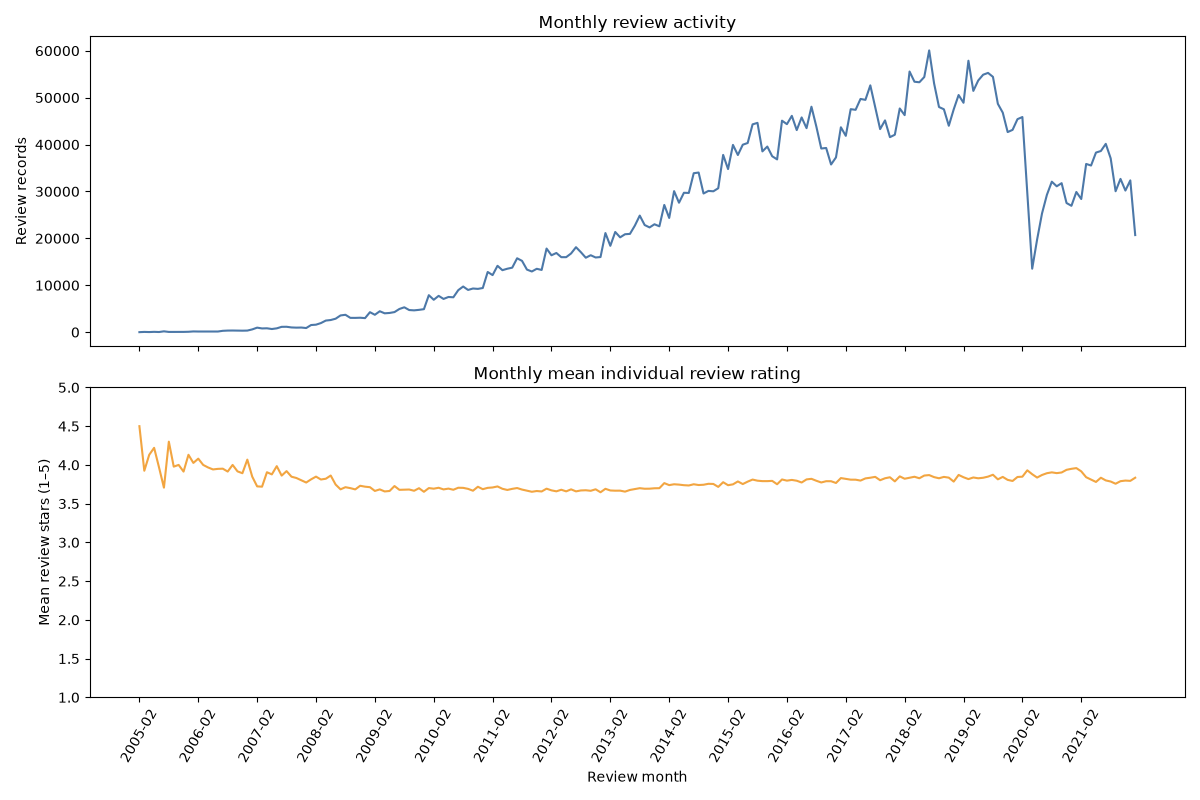

Currently open: 3,773,770 reviews; 3,773,770 valid ratings; mean rating=3.832
  Supplied reviews per restaurant: n=34,987; mean=107.86; median=41.00; min=5.00; max=7673.00
  Valid check-ins per restaurant (including zero): n=34,987; mean=193.13; median=52.00; min=0.00; max=40109.00
Currently closed: 950,701 reviews; 950,701 valid ratings; mean rating=3.643
  Supplied reviews per restaurant: n=17,281; mean=55.01; median=25.00; min=5.00; max=1810.00
  Valid check-ins per restaurant (including zero): n=17,281; mean=101.73; median=33.00; min=0.00; max=3596.00
Aggregate reconciliation checks passed.


In [6]:
review_path = DATASETS["reviews"]
if availability(review_path) != "present":
    raise FileNotFoundError(f"Reviews unavailable: {availability(review_path)}")

business_status = {row["business_id"]: row.get("is_open") for row in businesses if not is_missing(row.get("business_id"))}
review_month_count = Counter()
review_month_rating_count = Counter()
review_month_rating_sum = Counter()
review_status_count = Counter()
review_status_rating_count = Counter()
review_status_rating_sum = Counter()
review_rating_counts = Counter()
reviews_by_business = Counter()
review_date_min = review_date_max = None
review_records = invalid_review_dates = invalid_review_ratings = unmatched_reviews = 0

for review in read_jsonl_gz(review_path):
    review_records += 1
    business_id = review.get("business_id")
    status = business_status.get(business_id)
    unmatched_reviews += business_id not in business_status
    reviews_by_business[business_id] += 1
    review_status_count[status] += 1
    try:
        review_date = datetime.fromisoformat(review["date"])
        month = review_date.strftime("%Y-%m")
        review_month_count[month] += 1
        review_date_min = review_date if review_date_min is None else min(review_date_min, review_date)
        review_date_max = review_date if review_date_max is None else max(review_date_max, review_date)
    except (KeyError, TypeError, ValueError):
        invalid_review_dates += 1
        month = None
    try:
        rating = float(review["stars"])
        if not math.isfinite(rating) or not 1 <= rating <= 5:
            raise ValueError("rating outside expected 1–5 range")
        review_rating_counts[rating] += 1
        review_status_rating_count[status] += 1
        review_status_rating_sum[status] += rating
        if month is not None:
            review_month_rating_count[month] += 1
            review_month_rating_sum[month] += rating
    except (KeyError, TypeError, ValueError):
        invalid_review_ratings += 1

print(f"Review records read: {review_records:,}")
print(f"Review date range: {review_date_min} to {review_date_max}")
print(f"Missing/unparseable review dates: {invalid_review_dates:,}")
print(f"Missing/invalid review ratings: {invalid_review_ratings:,}")
print(f"Reviews with unmatched restaurant IDs: {unmatched_reviews:,}")
print(f"Restaurants with reviews: {sum(reviews_by_business[i] > 0 for i in valid_business_ids):,} / {len(valid_business_ids):,}")
print("Review records by current restaurant status:", dict(review_status_count))
valid_rating_count = sum(review_rating_counts.values())
mean_review_rating = sum(r * c for r, c in review_rating_counts.items()) / valid_rating_count if valid_rating_count else math.nan
print(f"Mean individual review rating: {mean_review_rating:.3f}")
print("Individual review rating distribution:", dict(sorted(review_rating_counts.items())))
count_mismatches = sum(reviews_by_business[row["business_id"]] != row.get("review_count") for row in businesses)
print(f"Restaurants whose supplied review total differs from business review_count: {count_mismatches:,}")
print("Stored review_count and supplied review totals may differ due to snapshot/filtering differences.")

months = sorted(review_month_count)
if months:
    monthly_means = [review_month_rating_sum[m] / review_month_rating_count[m] if review_month_rating_count[m] else math.nan for m in months]
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(months, [review_month_count[m] for m in months], color="#4C78A8")
    axes[0].set_title("Monthly review activity")
    axes[0].set_ylabel("Review records")
    axes[1].plot(months, monthly_means, color="#F2A541")
    axes[1].set_title("Monthly mean individual review rating")
    axes[1].set_ylabel("Mean review stars (1–5)")
    axes[1].set_xlabel("Review month")
    axes[1].set_ylim(1, 5)
    axes[1].set_xticks(months[::12])
    axes[1].tick_params(axis="x", rotation=60)
    fig.tight_layout()
    plt.show()

for status, label in status_labels.items():
    count = review_status_rating_count[status]
    mean = review_status_rating_sum[status] / count if count else math.nan
    restaurant_counts = [reviews_by_business[row["business_id"]] for row in businesses if row.get("is_open") == status]
    print(f"{label}: {review_status_count[status]:,} reviews; {count:,} valid ratings; mean rating={mean:.3f}")
    print(f"  Supplied reviews per restaurant: {describe(restaurant_counts)}")
    event_counts = [checkins_by_business[row["business_id"]] for row in businesses if row.get("is_open") == status]
    print(f"  Valid check-ins per restaurant (including zero): {describe(event_counts)}")

# Reconcile totals so parsing or grouping mistakes cannot silently pass.
assert sum(review_month_count.values()) + invalid_review_dates == review_records
assert sum(review_status_count.values()) == review_records
assert valid_rating_count + invalid_review_ratings == review_records
assert sum(reviews_by_business.values()) == review_records
assert sum(checkin_month_counts.values()) == checkin_event_count
assert sum(checkin_status_counts.values()) == checkin_event_count
print("Aggregate reconciliation checks passed.")


## 7. Optional filtered tips file (not reviews)

Tips are a separate Yelp data type and are not substituted for reviews. This small summary checks whether the filtered tips file is available and, if so, counts its records and date range without inspecting text or performing sentiment analysis.

In [7]:
tips_path = DATASETS["tips"]
if availability(tips_path) != "present":
    print(f"Tips dataset unavailable: {availability(tips_path)}")
else:
    tips_count = 0
    tips_min = None
    tips_max = None
    tips_bad_dates = 0
    for tip in read_jsonl_gz(tips_path):
        tips_count += 1
        try:
            tip_date = datetime.strptime(tip["date"], "%Y-%m-%d %H:%M:%S")
            tips_min = tip_date if tips_min is None else min(tips_min, tip_date)
            tips_max = tip_date if tips_max is None else max(tips_max, tip_date)
        except (KeyError, TypeError, ValueError):
            tips_bad_dates += 1
    print(f"Filtered tip records: {tips_count:,}")
    print(f"Tip date range (valid dates): {tips_min} to {tips_max}")
    print(f"Missing/unparseable tip dates: {tips_bad_dates:,}")

Filtered tip records: 649,150
Tip date range (valid dates): 2009-04-16 13:11:49 to 2022-01-19 18:42:44
Missing/unparseable tip dates: 0


## 8. Initial findings and limitations

### Findings from the executed notebook

- **Restaurant sample:** 52,268 unique restaurants; 34,987 (66.9%) labeled open and 17,281 (33.1%) labeled closed. There are no missing/duplicate business IDs or unexpected status labels, and every record includes the Restaurants category.
- **Business summaries:** Reported review counts are strongly right-skewed (median 33, mean 87.27, maximum 7,568). Currently open restaurants have a higher median reported count (40 versus 24); average business stars are similar (3.52 versus 3.50).
- **Reviews:** 4,724,471 records from February 16, 2005 through January 19, 2022 cover all 52,268 restaurants. There are no unmatched restaurant IDs, invalid dates, or invalid ratings. The overall individual-review mean is 3.794 stars; review-weighted means are 3.832 for currently open restaurants and 3.643 for currently closed restaurants. These differ from averages of business-level ratings because the units and weights differ.
- **Review coverage:** Supplied review totals differ from stored `review_count` for 32,018 restaurants. They are reported separately rather than assumed identical; the files do not establish the reason for the discrepancies.
- **Check-ins:** 8,515,127 valid events from December 30, 2009 through January 19, 2022 cover 51,302 restaurants (98.2%). There are no unmatched IDs, empty date strings, or unparseable timestamps. Median check-in counts, including restaurants with zero events, are 52 for currently open restaurants and 33 for currently closed restaurants.
- **Time patterns:** Monthly review volume rises over much of the observation period, while check-ins peak earlier and decline before 2020. Both show a sharp drop in early 2020 and a partial recovery. Monthly average review ratings are relatively stable in the later years, roughly 3.7–4.0. These aggregate plots do not establish causes or restaurant-specific warning signs.
- **Other quality checks:** Business stars, review counts, and coordinates pass basic range checks. Hours are missing for 13.9% of restaurants and attributes for 1.1%. The separate tips file contains 649,150 records from April 16, 2009 through January 19, 2022, with no invalid dates; tips are not treated as reviews.
- **Verification:** All code cells executed sequentially in a fresh Python process using the project's virtual environment; text and figure outputs are saved in this notebook. Review record/date/rating/status totals and check-in event totals reconcile. The full compressed review file was streamed once, retaining only small aggregates and counts per business.

### Limitations

The filtered restaurant sample is not representative of all restaurants; Yelp activity also depends on platform use, geography, business age, and observation length. Review-weighted mean ratings give more weight to restaurants with more reviews. Differences between stored business summaries and individual reviews may reflect filtering or snapshot differences, but this explanation has not been verified. Exact duplicate review records were not checked; retaining every review ID would increase memory use, and counts here are counts of supplied records.

`is_open` is a snapshot label with no exact closure date. The last review or check-in is not a closure date, and historical records grouped by current status do not establish changes before closure. Edge months may be incomplete (the files end on January 19, 2022); aggregate activity and rating changes can reflect changing restaurant composition rather than changes within restaurants. Early monthly rating averages have fewer observations and are less stable. Check-in absence and missing hours/attributes are not evidence of closure.

This completes preliminary exploratory analysis only. No modeling, sentiment analysis, or advanced feature engineering is performed.
